# Hybrid 01 · Multimodal alignment and frozen image embeddings

**Objective:** show how each tissue's 24 recorded features are joined to its specular microscopy image, how the image becomes a 2048-d frozen ResNet-50 embedding, and how PCA reduces that embedding inside the training folds.

**Derived from:** `notebooks/images/03_multimodal_data_alignment.ipynb`, `notebooks/images/07_hybrid_evaluation.ipynb` (Sections 1–3), `scripts/train_hybrid_grading_model.py`.
**Runtime:** about 1 minute (re-extracts 8 embeddings to check the cache; set `REEXTRACT_ALL = True` to re-check all 1,009, ≈3 min on GPU).

Locate the project from this notebook's folder and import the shared project modules.

In [1]:
import sys
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
REEXTRACT_ALL = False
print("Data:", ms.DATA_PATH.name, cs.sha256(ms.DATA_PATH), "| embeddings:", cs.EMBEDDING_PATH.name, cs.sha256(cs.EMBEDDING_PATH))

Data: cleaned_grading_dataset.xlsx 0ce9b384a51a4c47 | embeddings: resnet50_imagenet_fullres.npz 883d4a1723a17be7


## 1. Matching tabular records to images

Match the cleaned dataset to the image manifest on a normalised `Tissue_ID` (whitespace and case differences in the source IDs).

In [2]:
tabular = pd.read_excel(ms.DATA_PATH)
manifest = pd.read_csv(cs.MANIFEST_PATH)
tabular["Match_ID"] = tabular["Tissue_ID"].map(cs.normalize_id)
manifest["Match_ID"] = manifest["Tissue_ID"].map(cs.normalize_id)

tab_ids, img_ids = set(tabular["Match_ID"]), set(manifest["Match_ID"])
assert tabular["Match_ID"].is_unique and manifest["Match_ID"].is_unique
pd.Series({
    "Tabular records": len(tab_ids),
    "Image manifest records": len(img_ids),
    "Matched": len(tab_ids & img_ids),
    "Tabular records without an image": len(tab_ids - img_ids),
    "Images without a tabular record": len(img_ids - tab_ids),
}).to_frame("Count")

,Count
Tabular records,1054
Image manifest records,1024
Matched,1024
Tabular records without an image,30
Images without a tabular record,0


Every matched image carries the same grade as its record (checked in Images 01). Build the image cohort K2: labelled, image-matched tissues, excluding two IDs whose duplicate image files contain different images (flagged for manual review rather than choosing one arbitrarily).

In [3]:
k2, folds = cs.image_cohort()
print("K2 tissues:", len(k2), "| inferred donors:", k2["Donor_Group"].nunique())
k2[ms.TARGET].value_counts().reindex(cs.CLASSES).to_frame("Tissues")

K2 tissues: 1009 | inferred donors: 770


,Tissues
Tissue_Grade_Clean,
A+,530
A,314
B,165


Every K2 image must exist and have the training size (1296 × 972, 8-bit greyscale); the application flags any other size for review.

In [4]:
image_paths = k2["Selected_Image"].map(lambda p: cs.IMAGE_DIR / Path(p).name)
properties = []
for path in image_paths:
    with Image.open(path) as img:  # reads the header only
        properties.append((img.size, img.mode))
print(pd.Series(properties).value_counts().rename("Images").to_string())
assert set(properties) == {((1296, 972), "L")}

((1296, 972), L)    1009


## 2. Frozen ResNet-50 image embeddings

The extractor from notebook 07: ImageNet ResNet-50 with its classification layer removed, applied to the **full-resolution** image (replicated to 3 channels, ImageNet normalisation). Global average pooling turns the final feature maps into one 2048-d vector. The network is frozen and never sees the grades, so extracting embeddings once for all tissues does not leak labels.

In [5]:
from torchvision.models import ResNet50_Weights, resnet50

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_image(path):
    with Image.open(path) as img:
        array = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
    return torch.from_numpy(array)[None].repeat(3, 1, 1)


@torch.inference_mode()
def extract_embeddings(paths, batch_size=4):
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    model.fc = torch.nn.Identity()
    model.eval().to(device)
    mean, std = IMAGENET_MEAN.to(device), IMAGENET_STD.to(device)
    output = []
    for start in range(0, len(paths), batch_size):
        batch = torch.stack([load_image(p) for p in paths[start:start + batch_size]])
        output.append(model(((batch.to(device) - mean) / std)).float().cpu().numpy())
    return np.concatenate(output)

Load the cached embeddings (computed once in notebook 07) and confirm their rows are in K2 order.

In [6]:
cached = np.load(cs.EMBEDDING_PATH, allow_pickle=True)
assert list(cached["tissue_ids"]) == list(k2["Tissue_ID"]), "Cached embeddings are not aligned with K2"
embeddings = cached["embeddings"]
assert np.isfinite(embeddings).all()
print("Cached embedding matrix:", embeddings.shape, "| device for re-extraction:", device)

Cached embedding matrix: (1009, 2048) | device for re-extraction: cuda


Re-extract a sample of images now and compare with the cache, to verify the cache came from this extractor (small differences are floating-point and GPU rounding).

In [7]:
sample = np.arange(len(k2)) if REEXTRACT_ALL else np.linspace(0, len(k2) - 1, 8).astype(int)
fresh = extract_embeddings([image_paths.iloc[i] for i in sample])
relative = np.linalg.norm(fresh - embeddings[sample], axis=1) / np.linalg.norm(embeddings[sample], axis=1)
print(f"Re-extracted {len(sample)} images; relative L2 difference from cache: max {relative.max():.2e}, median {np.median(relative):.2e}")
assert relative.max() < 1e-2

Re-extracted 8 images; relative L2 difference from cache: max 1.96e-04, median 0.00e+00


## 3. Combining the 24 recorded features with the image embedding

Join each tissue's 6 Konan measurements and 18 slit-lamp findings with its embedding by `Tissue_ID`, giving one row per tissue.

In [8]:
X, y, donors = cs.feature_matrix(k2)
print("Feature matrix:", X.shape, "= 24 recorded features +", len(cs.EMBEDDING_COLUMNS), "embedding dimensions")
print("Konan features:", ms.NUMERIC_FEATURES)
print("Slit-lamp features:", len(ms.CLINICAL_FEATURES), f"({len(ms.CLINICAL_BINARY_FEATURES)} binary, {len(ms.CLINICAL_CATEGORICAL_FEATURES)} categorical)")

Feature matrix: (1009, 2072) = 24 recorded features + 2048 embedding dimensions
Konan features: ['ECD_CD_cells_per_mm2', 'CV', 'HEX_percent', 'SD', 'Total_Cell_Count', 'Total_Area_um2']
Slit-lamp features: 18 (13 binary, 5 categorical)


The hybrid preprocessing is one `ColumnTransformer`: the tabular branch (median imputation + scaling for Konan values; missing-as-its-own-category one-hot encoding for slit-lamp findings) and the image branch (standardise → PCA).

In [9]:
cs.show_source(ms.make_preprocessor, cs.preprocessor)

def make_preprocessor(
    numeric=NUMERIC_FEATURES,
    binary=CLINICAL_BINARY_FEATURES,
    categorical=CLINICAL_CATEGORICAL_FEATURES,
    scale_numeric=True,
):
    """Build the 04 preprocessing for any subset of feature groups.

    Pass an empty list to drop a group, e.g. make_preprocessor(binary=[],
    categorical=[]) for numeric-only models. Missing clinical values are
    kept as their own category, as in 04.
    """
    transformers = []

    if numeric:
        steps = [("imputer", SimpleImputer(strategy="median"))]
        if scale_numeric:
            steps.append(("scaler", StandardScaler()))
        transformers.append(("numeric", Pipeline(steps), list(numeric)))

    if binary:
        transformers.append((
            "clinical_binary",
            Pipeline([
                ("imputer", SimpleImputer(strategy="constant", fill_value=-1)),
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]),
            list(binary),
        ))

    if cat

Fit the preprocessor on the **training part of one donor-grouped fold only** and transform the held-out part, as every later experiment does inside its pipeline.

In [10]:
train, test = next(ms.iter_donor_folds(folds, k2["Tissue_ID"], repeat=0))
assert set(donors[train]).isdisjoint(donors[test])
pre = cs.preprocessor(n_components=16).fit(X.iloc[train], y[train])
names = pre.get_feature_names_out()
print(f"Fitted on {len(train)} training tissues; transforms {len(test)} held-out tissues to {pre.transform(X.iloc[test]).shape[1]} model inputs")
print("Tabular columns:", sum(n.startswith("tabular__") for n in names), "| image PCA components:", sum(n.startswith("image__") for n in names))

Fitted on 808 training tissues; transforms 201 held-out tissues to 85 model inputs
Tabular columns: 69 | image PCA components: 16


A missing slit-lamp finding becomes its own category (`-1`), not "No" (`0`): one binary finding expands to three one-hot columns.

In [11]:
[n for n in names if "Stroma_Has_Scar" in n]

['tabular__clinical_binary__Stroma_Has_Scar_-1.0',
 'tabular__clinical_binary__Stroma_Has_Scar_0.0',
 'tabular__clinical_binary__Stroma_Has_Scar_1.0']

## 4. Why PCA?

2048 embedding dimensions against ~440 training tissues per fold of the primary cohort: unreduced, the image would swamp the 24 recorded features in a Random Forest's feature sampling and invite overfitting. PCA keeps the main directions of image variation. It is unsupervised (never sees the grades) and is refitted inside each training fold.

In [12]:
k3, folds3, _ = cs.primary_cohort()
X3, y3, _ = cs.feature_matrix(k3)
train3, _ = next(ms.iter_donor_folds(folds3, k3["Tissue_ID"], repeat=0))
image_branch = cs.preprocessor(n_components=128, tabular=False).fit(X3.iloc[train3])
cumulative = np.cumsum(image_branch.named_transformers_["image"].named_steps["pca"].explained_variance_ratio_)
ks = [8, 16, 32, 64, 128]
pd.Series({k: cumulative[k - 1] for k in ks}, name="Cumulative explained variance").rename_axis("PCA components").to_frame().round(3)

,Cumulative explained variance
PCA components,
8,0.297
16,0.404
32,0.533
64,0.675
128,0.819


Cumulative explained variance on one primary-cohort training fold, with the PCA sizes searched in notebooks 07–15 marked (the deployed model uses 32).

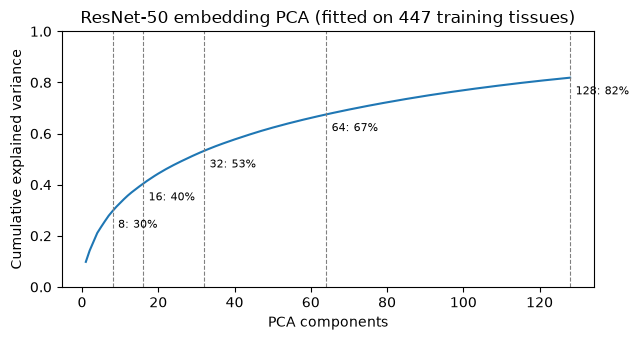

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(np.arange(1, 129), cumulative, color="tab:blue")
for k in ks:
    ax.axvline(k, color="grey", lw=0.8, ls="--")
    ax.annotate(f"{k}: {cumulative[k - 1]:.0%}", (k, cumulative[k - 1]), textcoords="offset points", xytext=(4, -12), fontsize=8)
ax.set(xlabel="PCA components", ylabel="Cumulative explained variance", ylim=(0, 1),
       title=f"ResNet-50 embedding PCA (fitted on {len(train3)} training tissues)")
plt.tight_layout()
plt.show()

## Interpretation

- All 1,024 manifest images match a tabular record with the same grade; 1,009 labelled, unambiguous tissues form the image cohort (K2), all at 1296 × 972.
- The cached embeddings are aligned with K2 by `Tissue_ID` and reproduce when re-extracted.
- Preprocessing and PCA sit inside the model pipeline, so they are refitted on training tissues in every fold; missing findings stay distinguishable from negative findings.

**Limitations:** the embeddings are generic ImageNet features, frozen and not adapted to specular microscopy. The PCA components have no clinical meaning and are not interpreted individually.